#
Regresión Lineal

## Librerias y Configuración

In [23]:
import warnings
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, classification_report, 
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

warnings.filterwarnings("ignore") 
np.set_printoptions(precision=4, suppress=True) # El numero de arreglos que quiero que traiga
pd.set_option("display.float_format", "{:.4f}".format)

In [29]:
#Plantilla de construcción de conjunto de pruebas y testeo

df = pd.read_csv("../data/df_final.csv")

numeric_features = [
    "age",
    "baseline_bmi",
    "baseline_charlson_comorbidity_index",
    "length_of_stay_days",
    "icu_days",
    "news2_acuity_score",
    "revisit_count",
    "n_meds",
    "n_high_risk_meds",
    "serum_creatinine_mg_dl",
    "hemoglobin_g_dl",
    "spo2_percent",
    "respiratory_rate_bpm",
    "heart_rate_bpm",
    "systolic_bp_mmhg",
    "white_blood_cell_count",
    "blood_glucose_mg_dl"
]

categoric_features = [
    "discharge_disposition",
    "disease_category",
    "disease_severity",
    "department",
    "admission_urgency",
    "encounter_type",
    "primary_insurance_provider",
    "socioeconomic_tier",
    "residential_zone",
    "smoker_status",
    "gender",
    "procedure_complexity",
    "hospital_acquired_infection"   
]

y = df["readmission_30d"].copy()
X = df[numeric_features + categoric_features]

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")



#Particionmiento de datos en train y test, con estratificación para mantener la proporción de clases en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          
    random_state=42,         
    stratify=y              
)


#Preprocesamiento de daots
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoric_features)
    ],
    remainder="drop"
)



X shape: (13214, 30)
y shape: (13214,)


In [34]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(   
     max_iter=1000, # Se aumento porque depsues del preprocesamiento 
                    # auemnta el numero de columnas y el valor por defecto
                    # no alacanza a converger            
    random_state=42,))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}
    
cv_results = cross_validate(
    gb_model,
    X_train, y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)



In [35]:
print("RESULTADOS CROSS-VALIDATION 5 FOLDS")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric:12} - Media: {scores.mean():.4f}")


gb_model.fit(X_train, y_train)

y_pred = gb_model.predict(X_test)
y_proba = gb_model.predict_proba(X_test)[:, 1]

print("PREDICCIONES")
print(classification_report(y_test, y_pred, target_names=["No reingreso", "Reingreso"]))
print(f"AUC-ROC Test: {roc_auc_score(y_test, y_proba):.4f}")

RESULTADOS CROSS-VALIDATION 5 FOLDS
accuracy     - Media: 0.7295
precision    - Media: 0.6323
recall       - Media: 0.4325
f1           - Media: 0.5136
roc_auc      - Media: 0.7733
PREDICCIONES
              precision    recall  f1-score   support

No reingreso       0.76      0.88      0.81      1770
   Reingreso       0.63      0.43      0.51       873

    accuracy                           0.73      2643
   macro avg       0.69      0.65      0.66      2643
weighted avg       0.72      0.73      0.71      2643

AUC-ROC Test: 0.7767


In [30]:
# Regesion logistica
RegLog= LogisticRegression(   
     max_iter=1000, # Se aumento porque depsues del preprocesamiento 
                    # auemnta el numero de columnas y el valor por defecto
                    # no alacanza a converger            
    random_state=42,)
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
RegLog.fit(X_train_p, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [31]:
#Evaluacion
y_pred_lr = RegLog.predict(X_test_p)
y_proba_lr = RegLog.predict_proba(X_test_p)[:, 1]

In [32]:
#Resultados de la Evalucion
print("\n--- Logistic Regression ---")
print(f"Accuracy : {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"AUC-ROC  : {roc_auc_score(y_test, y_proba_lr):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr,
                            target_names=["No Readmisión (0)", "Readmisión (1)"],
                            zero_division=0))


--- Logistic Regression ---
Accuracy : 0.7287
Precision: 0.6309
Recall   : 0.4307
F1-score : 0.5119
AUC-ROC  : 0.7767

Classification Report:
                   precision    recall  f1-score   support

No Readmisión (0)       0.76      0.88      0.81      1770
   Readmisión (1)       0.63      0.43      0.51       873

         accuracy                           0.73      2643
        macro avg       0.69      0.65      0.66      2643
     weighted avg       0.72      0.73      0.71      2643



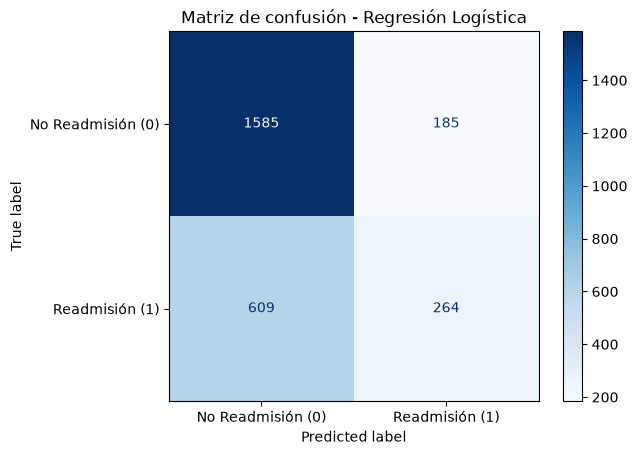

In [28]:
cm = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(cm, display_labels=["No Readmisión (0)", "Readmisión (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Regresión Logística")
plt.show()

## 
Conclusiones


- Se detectan pocos reingresos
- La regresión logística acierta el 70 % de las veces, pero eso es solo 3 puntos mejor que decir siempre ‘no reingresa’, lo que signifca que 3 pacientes mas acertados por cada 100
- 3 de cada 10 reingresosos son reales, y casi 4 de cada 10 de sus alertas son falsas alarmas (185)
- El AUC de 0.70 me indica que el modelo si ve algo en los datos, pero no sepra muy bine a los dos grupos
